# Notebook 12 – Business Insights

Move from **visualization → observation → insight → action**.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


In [2]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
overall = df.ChurnFlag.mean()
print(f"Customers: {len(df):,} | Overall churn: {overall:.1%} | Monthly recurring revenue (MRR): ${df.MonthlyCharges.sum():,.0f}")

Customers: 7,043 | Overall churn: 26.5% | Monthly recurring revenue (MRR): $456,117


### Topic Explanation

This topic translates observed data patterns into business meaning and practical actions, while keeping conclusions tied to the evidence.

## 1. Revenue at risk (business impact)

In [3]:
churned = df[df.Churn == "Yes"]
mrr_lost = churned.MonthlyCharges.sum()
print(f"Monthly revenue of churned customers: ${mrr_lost:,.0f}  ({mrr_lost / df.MonthlyCharges.sum():.1%} of MRR)")
print(f"Customer churn rate: {overall:.1%}  vs  revenue churn rate: {mrr_lost / df.MonthlyCharges.sum():.1%}")
print(f"Avg bill churned ${churned.MonthlyCharges.mean():.1f} vs retained ${df[df.Churn=='No'].MonthlyCharges.mean():.1f}")

Monthly revenue of churned customers: $139,131  (30.5% of MRR)
Customer churn rate: 26.5%  vs  revenue churn rate: 30.5%
Avg bill churned $74.4 vs retained $61.3


**Observation:** 26.5% of customers churned, but they represent about 30.5% (≈ \$139k) of monthly recurring revenue.

**Insight:** Revenue churn is *higher* than customer churn because churners pay more than average (≈ \$74 vs ≈ \$61): the company is losing its more valuable customers.

**Recommended action:** Prioritise retention spend by revenue at risk, not by head-count.

### Topic Explanation

This topic translates observed data patterns into business meaning and practical actions, while keeping conclusions tied to the evidence.

## 2. Contract type – the biggest lever

In [4]:
ct = df.groupby("Contract").agg(customers=("ChurnFlag", "size"), churn_pct=("ChurnFlag", "mean"), avg_bill=("MonthlyCharges", "mean"))
ct["share_%"] = ct.customers / len(df) * 100
ct["churn_pct"] *= 100
ct.round(1)

,customers,churn_pct,avg_bill,share_%
Contract,,,,
Month-to-month,3875,42.7,66.4,55.0
One year,1473,11.3,65.0,20.9
Two year,1695,2.8,60.8,24.1


**Observation:** Month-to-month customers are 55% of the base and churn at ≈ 43%; one-year ≈ 11%; two-year ≈ 3%.

**Insight:** Month-to-month customers produce the majority of churn (a *flexibility* problem, not a *price* problem – their average bill is similar to the other contracts).

**Recommended action:** Offer discounts/free add-ons for moving month-to-month customers to 12-month contracts, targeted at those with tenure of 6–12 months.

### Topic Explanation

This topic translates observed data patterns into business meaning and practical actions, while keeping conclusions tied to the evidence.

## 3. Early-life churn – the first year

Churn rate tenure<=12: 47.4%  | tenure>24: 14.0%
Share of all churners who left within first 12 months: 55.5%


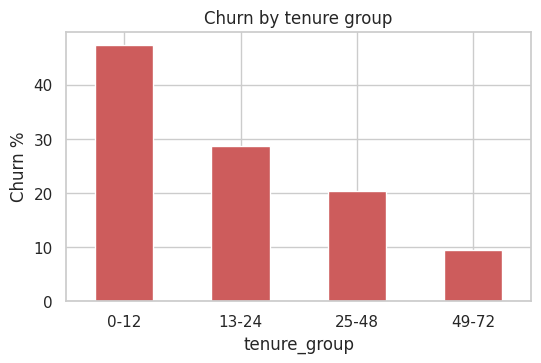

In [5]:
early = df.tenure <= 12
print(f"Churn rate tenure<=12: {df[early].ChurnFlag.mean():.1%}  | tenure>24: {df[df.tenure>24].ChurnFlag.mean():.1%}")
print(f"Share of all churners who left within first 12 months: {df[df.Churn=='Yes'].tenure.le(12).mean():.1%}")
g = df.groupby("tenure_group", observed=False).ChurnFlag.agg(["mean", "size"]); g["mean"] *= 100
ax = g["mean"].plot(kind="bar", color="indianred", figsize=(6, 3.5)); ax.set_ylabel("Churn %"); ax.set_title("Churn by tenure group"); plt.xticks(rotation=0); plt.show()

**Observation:** About 47% of customers in their first year churn, versus 14% of those beyond year two; roughly 56% of all churners left within their first 12 months.

**Insight:** The first year is the 'danger zone' of the customer lifecycle: retention work in the onboarding period yields the largest benefit.

**Recommended action:** Introduce an onboarding programme (welcome call, 90-day check-in, early-life offers) and monitor 3-, 6- and 12-month churn.

### Topic Explanation

This topic focuses on fibre optic – high price, high churn. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Fibre optic – high price, high churn

In [6]:
fi = df.groupby("InternetService").agg(customers=("ChurnFlag", "size"), churn_pct=("ChurnFlag", "mean"), avg_bill=("MonthlyCharges", "mean"))
fi["churn_pct"] *= 100
display(fi.round(1))
tech = df[df.InternetService != "No"].groupby(["InternetService", "TechSupport"]).ChurnFlag.mean().mul(100).round(1).unstack()
display(tech)

,customers,churn_pct,avg_bill
InternetService,,,
DSL,2421,19.0,58.1
Fiber optic,3096,41.9,91.5
No,1526,7.4,21.1


TechSupport,No,Yes
InternetService,,
DSL,27.8,9.7
Fiber optic,49.4,22.6


**Observation:** Fibre customers pay ≈ \$91 (vs ≈ \$58 for DSL) and churn at ≈ 42% (vs ≈ 19%); within each internet type, customers with TechSupport churn far less.

**Insight:** Fibre is a premium product with a retention problem (possibly service quality, competitor offers or price-value perception). Support services are associated with loyalty.

**Recommended action:** Investigate fibre service quality/competition; bundle TechSupport/OnlineSecurity free for 3–6 months on new fibre customers and test the effect (A/B test, since correlation ≠ causation).

### Topic Explanation

This topic focuses on add-on services and loyalty. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 5. Add-on services and loyalty

,service,churn_% with,churn_% without
0,OnlineSecurity,14.6,41.8
1,OnlineBackup,21.5,39.9
2,DeviceProtection,22.5,39.1
3,TechSupport,15.2,41.6
4,StreamingTV,30.1,33.5
5,StreamingMovies,29.9,33.7


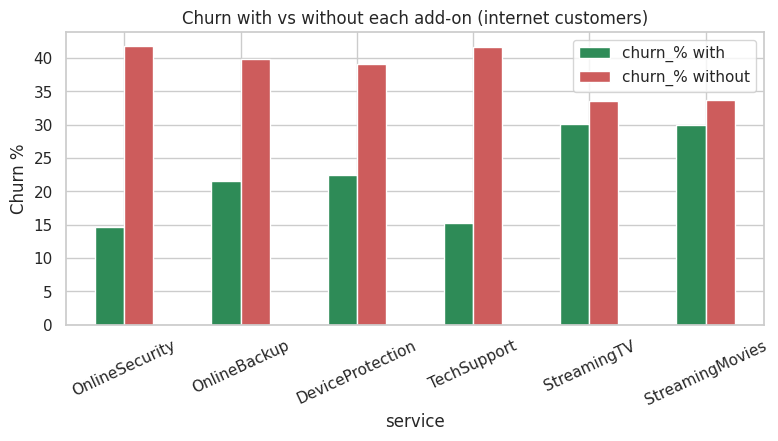

In [7]:
svc = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rows = []
internet = df[df.InternetService != "No"]
for s in svc:
    r = internet.groupby(s).ChurnFlag.mean().mul(100)
    rows.append((s, r.get("Yes"), r.get("No")))
res = pd.DataFrame(rows, columns=["service", "churn_% with", "churn_% without"]).round(1)
display(res)
res.set_index("service").plot(kind="bar", figsize=(9, 3.8), color=["seagreen", "indianred"]); plt.ylabel("Churn %"); plt.xticks(rotation=25); plt.title("Churn with vs without each add-on (internet customers)"); plt.show()

**Observation:** Among internet customers, those with OnlineSecurity, TechSupport, OnlineBackup or DeviceProtection churn at only about 35–60% of the rate of those without (e.g. 15% vs 42% for security and support); streaming add-ons show little protection (≈ 30% vs ≈ 34%).

**Insight:** Protective services (security/support/backup) are associated with retention; entertainment add-ons are not.

**Recommended action:** Prioritise cross-selling of security/support bundles to internet customers lacking them; do not expect streaming add-ons to improve retention.

### Topic Explanation

This topic focuses on payment method and billing. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 6. Payment method and billing

In [8]:
pm = df.groupby("PaymentMethod").agg(customers=("ChurnFlag", "size"), churn_pct=("ChurnFlag", "mean"), avg_tenure=("tenure", "mean"))
pm["churn_pct"] *= 100; pm["share_%"] = pm.customers / len(df) * 100
display(pm.round(1))
print(df.groupby("PaperlessBilling").ChurnFlag.mean().mul(100).round(1).to_dict())

,customers,churn_pct,avg_tenure,share_%
PaymentMethod,,,,
Bank transfer (automatic),1544,16.7,43.7,21.9
Credit card (automatic),1522,15.2,43.3,21.6
Electronic check,2365,45.3,25.2,33.6
Mailed check,1612,19.1,21.8,22.9


{'No': 16.3, 'Yes': 33.6}


**Observation:** Electronic-check payers (34% of customers) churn at ≈ 45%, against 15–19% for the other methods (automatic payments are lowest). Paperless billing customers churn more (≈ 34% vs ≈ 16%).

**Insight:** Automatic payment is likely a *proxy for commitment/convenience*; manual payment creates a recurring decision point to leave.

**Recommended action:** Encourage migration to bank-transfer or credit-card auto-pay (small incentive); examine why e-check customers are less satisfied.

### Topic Explanation

This topic focuses on customer demographics. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 7. Customer demographics

In [9]:
for c in ["SeniorCitizen", "Partner", "Dependents", "gender"]:
    print(c, df.groupby(c).ChurnFlag.mean().mul(100).round(1).to_dict())

SeniorCitizen {0: 23.6, 1: 41.7}
Partner {'No': 33.0, 'Yes': 19.7}
Dependents {'No': 31.3, 'Yes': 15.5}
gender {'Female': 26.9, 'Male': 26.2}


**Observation:** Seniors churn at ≈ 42% vs ≈ 24%; customers without partner/dependents churn more (≈ 33% / ≈ 31%) than those with (≈ 20% / ≈ 16%); gender makes no difference (≈ 27% each).

**Insight:** Household situation, not gender, relates to churn: single, dependent-free and senior customers are riskier segments.

**Recommended action:** Design senior-friendly offers and family/household plans; do not target by gender.

### Topic Explanation

This topic focuses on high-risk segment – compound effect. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 8. High-risk segment – compound effect

In [10]:
seg = df.query('Contract == "Month-to-month" and InternetService == "Fiber optic" and PaymentMethod == "Electronic check"')
print(f"Segment size: {len(seg):,} customers ({len(seg)/len(df):.1%} of base); churn = {seg.ChurnFlag.mean():.1%}")
print(f"MRR of segment: ${seg.MonthlyCharges.sum():,.0f}  | share of all churners: {seg.ChurnFlag.sum() / df.ChurnFlag.sum():.1%}")
safe = df.query('Contract == "Two year" and PaymentMethod in ["Bank transfer (automatic)", "Credit card (automatic)"]')
print(f"Safe segment (2-year + auto-pay): {len(safe):,} customers, churn = {safe.ChurnFlag.mean():.1%}")

Segment size: 1,307 customers (18.6% of base); churn = 60.4%
MRR of segment: $113,948  | share of all churners: 42.2%
Safe segment (2-year + auto-pay): 1,145 customers, churn = 2.8%


**Observation:** About 19% of customers (≈ 1,300; month-to-month + fibre + e-check) have a ≈ 60% churn rate and contribute roughly 42% of all churners. The 'safe' segment (two-year + auto-pay, ≈ 1,150 customers) churns at only ≈ 3%.

**Insight:** A simple three-attribute rule isolates a segment with more than twice the base churn rate – a ready-made targeting list for retention campaigns.

**Recommended action:** Start retention outreach with this segment, measuring uplift against a hold-out control group.

### Topic Explanation

This topic focuses on anomalies and data-driven curiosities. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 9. Anomalies and data-driven curiosities

In [11]:
print("Customers with tenure = 0 (new, not yet billed):", int((df.tenure == 0).sum()))
print("tenure at maximum (72) :", int((df.tenure == 72).sum()), "customers; churn =", f"{df[df.tenure==72].ChurnFlag.mean():.1%}")
print("tenure == 1            :", int((df.tenure == 1).sum()), "customers; churn =", f"{df[df.tenure==1].ChurnFlag.mean():.1%}")
no_net = df[df.InternetService == "No"]
print(f"No-internet customers: {len(no_net):,} ({len(no_net)/len(df):.1%}), avg bill ${no_net.MonthlyCharges.mean():.1f}, churn {no_net.ChurnFlag.mean():.1%}")

Customers with tenure = 0 (new, not yet billed): 11
tenure at maximum (72) : 362 customers; churn = 1.7%
tenure == 1            : 613 customers; churn = 62.0%
No-internet customers: 1,526 (21.7%), avg bill $21.1, churn 7.4%


**Observation:** There are 11 not-yet-billed customers (tenure 0); 362 customers sit at the 72-month cap with very low churn; 613 customers have 1 month of tenure with very high churn; about 22% of customers have no internet, pay ≈ \$21 and almost never churn.

**Insight:** The 72-month cap suggests the data window ends there, so real tenure is truncated (censored) for long-term customers. No-internet customers are a stable but low-value segment.

**Recommended action:** Treat the 72-month pile-up as censored data in modelling/survival analysis; protect the stable low-value segment cheaply (no premium spend).

## Executive Summary of Business Insights

| # | Insight | Opportunity |
|---|---|---|
| 1 | Churners carry ≈ 30% of MRR | Prioritise by revenue at risk |
| 2 | Month-to-month = 55% of customers, 43% churn | Convert to annual contracts |
| 3 | ≈ 47% churn in the first year | Onboarding & early-life programme |
| 4 | Fibre: high price, high churn | Service-quality & value investigation |
| 5 | Security/support add-ons ↔ lower churn | Cross-sell protective bundles |
| 6 | Electronic-check ↔ 45% churn | Move customers to auto-pay |
| 7 | Seniors / single households riskier | Targeted offers |
| 8 | Month-to-month × Fibre × e-check ≈ 60% churn | Top retention target list |
| 9 | tenure capped at 72, 11 unbilled customers | Handle censoring & structural blanks |

*Caveat: these are associations, not proven causes. Retention actions should be validated with controlled experiments.*